In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Reaidng the data 

In [2]:
df=pd.read_csv("D:\Courses\ML for data analysis (NTI)\Exercise\DT\Project Apartments Prices Dataset\Apartments Prices Dataset(Target column price).csv")
df.head()

<>:1: SyntaxWarning: "\C" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\C"? A raw string is also an option.
<>:1: SyntaxWarning: "\C" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\C"? A raw string is also an option.
C:\Users\abdoa\AppData\Local\Temp\ipykernel_26352\418571653.py:1: SyntaxWarning: "\C" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\C"? A raw string is also an option.
  df=pd.read_csv("D:\Courses\ML for data analysis (NTI)\Exercise\DT\Project Apartments Prices Dataset\Apartments Prices Dataset(Target column price).csv")


,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,"2,163,000 EGP",120 m²,2 rooms,3 bathroom,3,2025,Developer,Main Street,"18,025 EGP/M²",Installments,Semi Finished
1,"3,250,000 EGP",162 m²,3 rooms,2 bathroom,6,2024,Developer,Main Street,"20,062 EGP/M²",Cash or Installments,Semi Finished
2,"2,650,000 EGP",122 m²,3 rooms,1 bathroom,4,2024,Developer,Main Street,"21,721 EGP/M²",Cash or Installments,Semi Finished
3,"12,720,000 EGP",212 m²,4 rooms,3 bathroom,13,2027,Broker,Club,"60,000 EGP/M²",Cash or Installments,Extra Super Lux
4,"5,898,000 EGP",135 m²,2 rooms,1 bathroom,6,2025,Developer,Lake,"43,689 EGP/M²",Cash or Installments,Super Lux


# EDA

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5578 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   price           5572 non-null   str  
 1   area_sqm        5545 non-null   str  
 2   rooms           5550 non-null   str  
 3   bathrooms       5480 non-null   str  
 4   floor_level     5578 non-null   str  
 5   year_built      5578 non-null   int64
 6   seller_type     5387 non-null   str  
 7   view            5556 non-null   str  
 8   price_per_sqm   5534 non-null   str  
 9   payment_method  5566 non-null   str  
 10  finishing_type  5578 non-null   str  
dtypes: int64(1), str(10)
memory usage: 961.6 KB


In [9]:
df.describe()

,year_built
count,5578.000000
mean,2022.327178
std,8.431095
min,1915.000000
25%,2023.000000
50%,2025.000000
75%,2026.000000
max,2037.000000


In [10]:
df.isnull().sum().sort_values(ascending=False)

seller_type       191
bathrooms          98
price_per_sqm      44
area_sqm           33
rooms              28
view               22
payment_method     12
price               6
floor_level         0
year_built          0
finishing_type      0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(1298)

In [12]:
df.shape

(5578, 11)

In [13]:
df.drop_duplicates(inplace=True)

In [14]:
df.reset_index(drop=True,inplace=True)

In [15]:
df.duplicated().sum()

np.int64(0)

# Feature Engineering

In [16]:
df['seller_type'].value_counts()

seller_type
Broker                  3569
Developer                333
Private Owner            177
Compound Developer        20
Cash                       5
Cash or Installments       3
Installments               1
Name: count, dtype: int64

In [17]:
df['seller_type']=df['seller_type'].replace("Cash", np.nan)

In [18]:
df['seller_type']=df['seller_type'].replace("Cash or Installments", np.nan)

In [19]:
df['seller_type']=df['seller_type'].replace("Installments", np.nan)

In [20]:
df['seller_type'].value_counts()

seller_type
Broker                3569
Developer              333
Private Owner          177
Compound Developer      20
Name: count, dtype: int64

In [21]:
df['price'] = df['price'].str.replace(' EGP', '').str.replace(',', '').astype(float)

In [22]:
df['area_sqm'] = df['area_sqm'].str.replace(' m²', '', regex=False).astype(float)

In [23]:
df['bathrooms'] = df['bathrooms'].str.replace(' bathroom', '', regex=False).astype(float)

In [24]:
df['rooms']=df['rooms'].str.replace(' rooms','', regex=False).astype(float)

In [25]:
df['price_per_sqm']

0       18,025 EGP/M²
1       20,062 EGP/M²
2       21,721 EGP/M²
3       60,000 EGP/M²
4       43,689 EGP/M²
            ...      
4275    50,000 EGP/M²
4276    15,556 EGP/M²
4277    27,907 EGP/M²
4278    18,750 EGP/M²
4279    19,722 EGP/M²
Name: price_per_sqm, Length: 4280, dtype: str

In [26]:
# Strip out the units and commas first, then convert with errors='coerce'
df['price_per_sqm'] = (
    df['price_per_sqm']
    .str.replace('EGP/M²', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip() # cleans up any leftover trailing/leading spaces
)

df['price_per_sqm'] = pd.to_numeric(df['price_per_sqm'], errors='coerce')

# Check how many values became NaN (if any)
print(df['price_per_sqm'].isna().sum())

67


In [27]:
df['floor_level'] = pd.to_numeric(df['floor_level'], errors='coerce')

# Missing values and duplication

In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4280 entries, 0 to 4279
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   price           4274 non-null   float64
 1   area_sqm        4247 non-null   float64
 2   rooms           4252 non-null   float64
 3   bathrooms       4183 non-null   float64
 4   floor_level     4128 non-null   float64
 5   year_built      4280 non-null   int64  
 6   seller_type     4099 non-null   str    
 7   view            4259 non-null   str    
 8   price_per_sqm   4213 non-null   float64
 9   payment_method  4268 non-null   str    
 10  finishing_type  4280 non-null   str    
dtypes: float64(6), int64(1), str(4)
memory usage: 519.8 KB


In [29]:
df.isnull().sum().sort_values(ascending=False)

seller_type       181
floor_level       152
bathrooms          97
price_per_sqm      67
area_sqm           33
rooms              28
view               21
payment_method     12
price               6
year_built          0
finishing_type      0
dtype: int64

<Axes: ylabel='Frequency'>

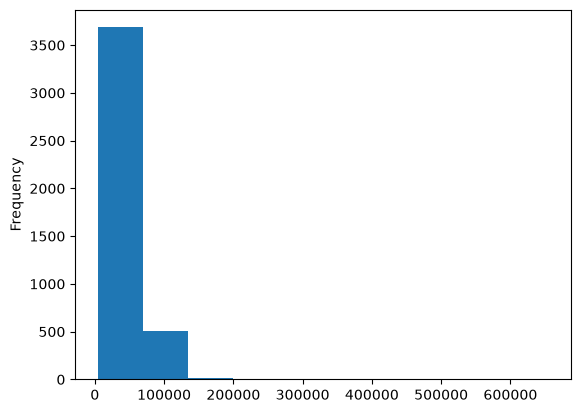

In [30]:
df['price_per_sqm'].plot(kind='hist')

In [31]:
df['price_per_sqm'].skew()

np.float64(6.577563855067383)

<Axes: ylabel='Frequency'>

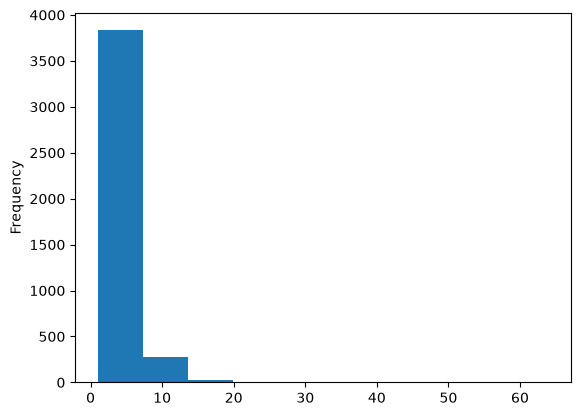

In [32]:
df['floor_level'].plot(kind='hist')

In [33]:
df['floor_level'].skew()

np.float64(4.552237794148692)

<Axes: ylabel='Frequency'>

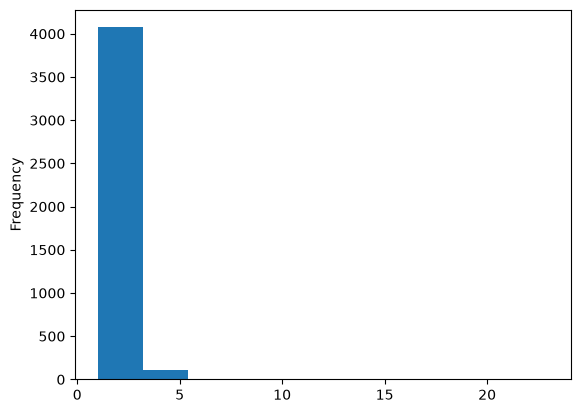

In [34]:
df['bathrooms'].plot(kind='hist')

In [35]:
df['bathrooms'].skew()

np.float64(4.840610648135993)

<Axes: ylabel='Frequency'>

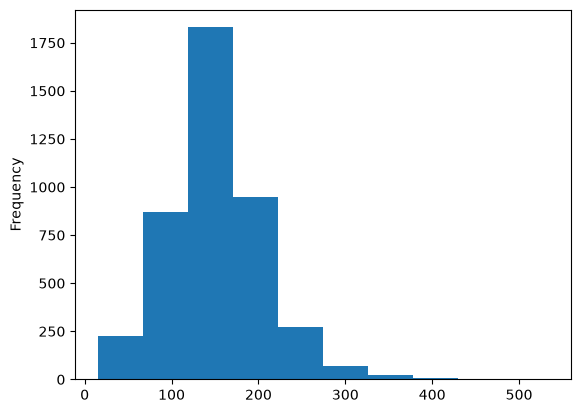

In [36]:
df['area_sqm'].plot(kind='hist')

In [37]:
df['area_sqm'].skew()

np.float64(0.7325684238767584)

<Axes: ylabel='Frequency'>

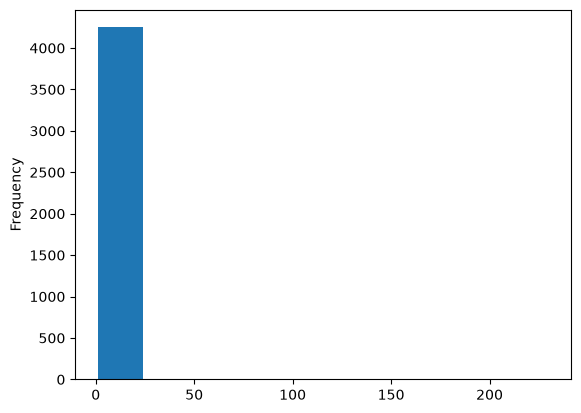

In [38]:
df['rooms'].plot(kind='hist')

In [39]:
df['rooms'].skew()

np.float64(47.843133437150385)

<Axes: ylabel='Frequency'>

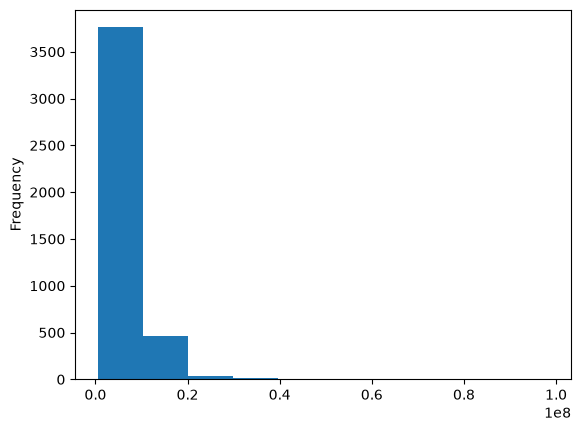

In [40]:
df['price'].plot(kind='hist')

In [41]:
df['price'].skew()

np.float64(5.754595146637905)

In [42]:
col=['floor_level','price_per_sqm','bathrooms','area_sqm','rooms','price']

In [43]:
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(missing_values=np.nan,strategy='median')
for i in col:
    df[[i]]=imputer.fit_transform(df[[i]])

In [44]:
obj_col=['seller_type','view','payment_method']

In [45]:
imputer=SimpleImputer(missing_values=np.nan,strategy='most_frequent')
for z in obj_col:
    df[[z]]=imputer.fit_transform(df[[z]])

In [46]:
df.isnull().sum().sort_values(ascending=False)

price             0
area_sqm          0
rooms             0
bathrooms         0
floor_level       0
year_built        0
seller_type       0
view              0
price_per_sqm     0
payment_method    0
finishing_type    0
dtype: int64

In [47]:
df.head()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,2163000.0,120.0,2.0,3.0,3.0,2025,Developer,Main Street,18025.0,Installments,Semi Finished
1,3250000.0,162.0,3.0,2.0,6.0,2024,Developer,Main Street,20062.0,Cash or Installments,Semi Finished
2,2650000.0,122.0,3.0,1.0,4.0,2024,Developer,Main Street,21721.0,Cash or Installments,Semi Finished
3,12720000.0,212.0,4.0,3.0,13.0,2027,Broker,Club,60000.0,Cash or Installments,Extra Super Lux
4,5898000.0,135.0,2.0,1.0,6.0,2025,Developer,Lake,43689.0,Cash or Installments,Super Lux


In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4280 entries, 0 to 4279
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   price           4280 non-null   float64
 1   area_sqm        4280 non-null   float64
 2   rooms           4280 non-null   float64
 3   bathrooms       4280 non-null   float64
 4   floor_level     4280 non-null   float64
 5   year_built      4280 non-null   int64  
 6   seller_type     4280 non-null   str    
 7   view            4280 non-null   str    
 8   price_per_sqm   4280 non-null   float64
 9   payment_method  4280 non-null   str    
 10  finishing_type  4280 non-null   str    
dtypes: float64(6), int64(1), str(4)
memory usage: 519.6 KB


# Visualization


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
 [Text(0, 0, '1.0'),
  Text(1, 0, '2.0'),
  Text(2, 0, '3.0'),
  Text(3, 0, '4.0'),
  Text(4, 0, '5.0'),
  Text(5, 0, '7.0'),
  Text(6, 0, '10.0'),
  Text(7, 0, '13.0'),
  Text(8, 0, '33.0'),
  Text(9, 0, '123.0'),
  Text(10, 0, '230.0')])

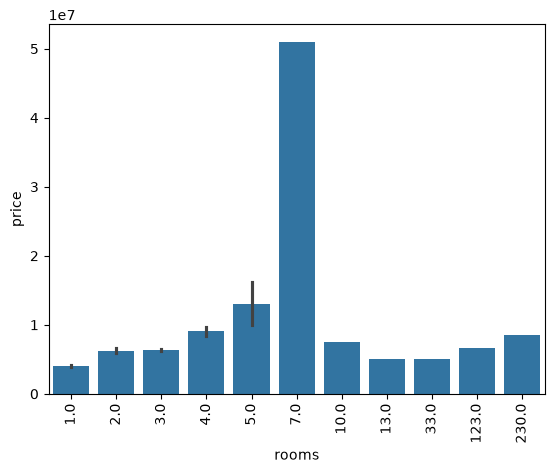

In [49]:
sns.barplot(data=df,x='rooms',y='price')
plt.xticks(rotation=90)

<Axes: xlabel='area_sqm', ylabel='price'>

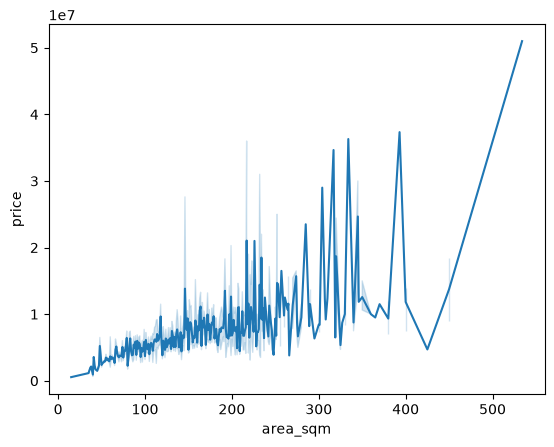

In [50]:
sns.lineplot(data=df,x='area_sqm',y='price')

(array([1900., 1920., 1940., 1960., 1980., 2000., 2020., 2040., 2060.]),
 [Text(1900.0, 0, '1900'),
  Text(1920.0, 0, '1920'),
  Text(1940.0, 0, '1940'),
  Text(1960.0, 0, '1960'),
  Text(1980.0, 0, '1980'),
  Text(2000.0, 0, '2000'),
  Text(2020.0, 0, '2020'),
  Text(2040.0, 0, '2040'),
  Text(2060.0, 0, '2060')])

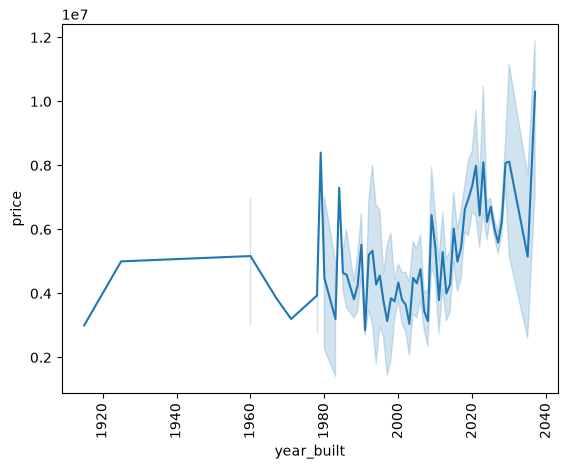

In [51]:
sns.lineplot(data=df,x='year_built',y='price')
plt.xticks(rotation=90)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
 [Text(0, 0, 'Main Street'),
  Text(1, 0, 'Club'),
  Text(2, 0, 'Lake'),
  Text(3, 0, 'Side Street'),
  Text(4, 0, 'Other'),
  Text(5, 0, 'Garden'),
  Text(6, 0, 'Sea View'),
  Text(7, 0, 'Pool'),
  Text(8, 0, 'Plaza'),
  Text(9, 0, 'Corner'),
  Text(10, 0, 'Nile View'),
  Text(11, 0, 'Back'),
  Text(12, 0, 'Golf Course')])

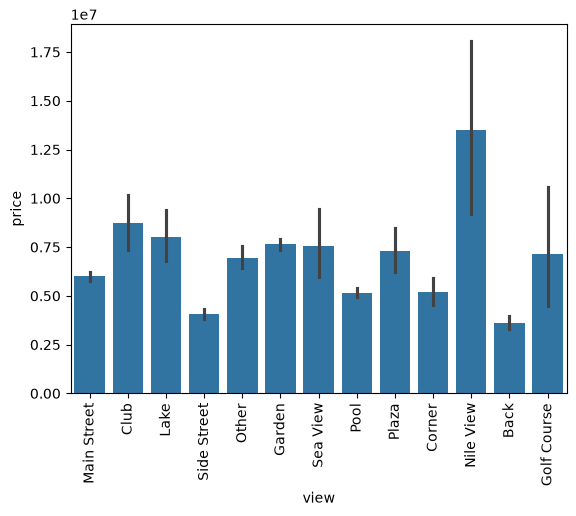

In [52]:
sns.barplot(data=df,x='view',y='price')
plt.xticks(rotation=90)

[Text(0, 0.5, 'price'),
 Text(0, 1.5, 'area_sqm'),
 Text(0, 2.5, 'rooms'),
 Text(0, 3.5, 'bathrooms'),
 Text(0, 4.5, 'floor_level'),
 Text(0, 5.5, 'year_built'),
 Text(0, 6.5, 'price_per_sqm')]

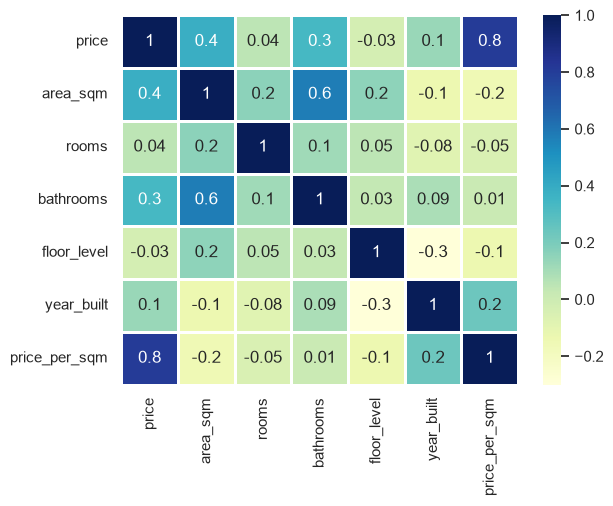

In [53]:
df_corr= df.select_dtypes(include='number')

sns.set(style='whitegrid')
plt.Figure(figsize=(15,6))

linewidths = 1

ax = sns.heatmap(df_corr.corr(), annot=True, fmt="0.1g", cmap="YlGnBu",linewidths=linewidths)


ax.set_xticklabels(df_corr.columns)  
ax.set_yticklabels(df_corr.columns)  


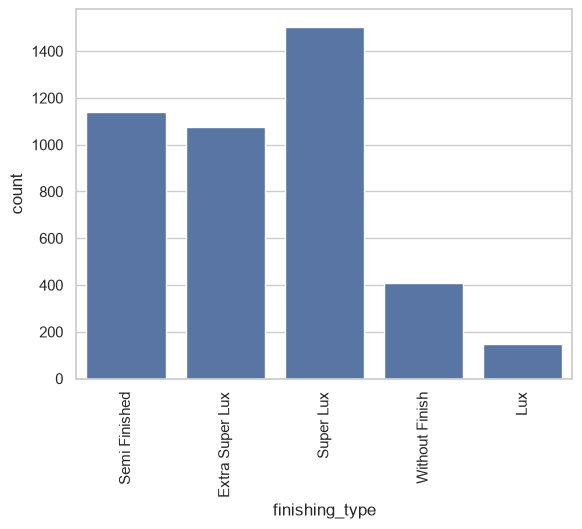

In [54]:
sns.countplot(x=df["finishing_type"])
plt.xticks(rotation=90)
plt.show()

# Preprocessing

In [55]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder


In [56]:
ohe=OneHotEncoder(sparse_output=False,
                  handle_unknown='ignore',
                  drop='first'
).set_output(transform='pandas')

In [57]:
df.head()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,2163000.0,120.0,2.0,3.0,3.0,2025,Developer,Main Street,18025.0,Installments,Semi Finished
1,3250000.0,162.0,3.0,2.0,6.0,2024,Developer,Main Street,20062.0,Cash or Installments,Semi Finished
2,2650000.0,122.0,3.0,1.0,4.0,2024,Developer,Main Street,21721.0,Cash or Installments,Semi Finished
3,12720000.0,212.0,4.0,3.0,13.0,2027,Broker,Club,60000.0,Cash or Installments,Extra Super Lux
4,5898000.0,135.0,2.0,1.0,6.0,2025,Developer,Lake,43689.0,Cash or Installments,Super Lux


In [58]:
col=['seller_type','payment_method']

In [59]:
for CO in col:
    Temp=ohe.fit_transform(df[[CO]])
    df=pd.concat([df,Temp],axis=1)

In [60]:
df.drop(['seller_type','payment_method'],axis=1,inplace=True)

In [61]:
df.reset_index(drop=True,inplace=True)

In [62]:
le=LabelEncoder()

In [63]:
C=['view','finishing_type']

In [64]:
for i in C:
    df[i]=le.fit_transform(df[[i]])

c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [65]:
df.head()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,view,price_per_sqm,finishing_type,seller_type_Compound Developer,seller_type_Developer,seller_type_Private Owner,payment_method_Cash or Installments,payment_method_Installments
0,2163000.0,120.0,2.0,3.0,3.0,2025,6,18025.0,2,0.0,1.0,0.0,0.0,1.0
1,3250000.0,162.0,3.0,2.0,6.0,2024,6,20062.0,2,0.0,1.0,0.0,1.0,0.0
2,2650000.0,122.0,3.0,1.0,4.0,2024,6,21721.0,2,0.0,1.0,0.0,1.0,0.0
3,12720000.0,212.0,4.0,3.0,13.0,2027,1,60000.0,0,0.0,0.0,0.0,1.0,0.0
4,5898000.0,135.0,2.0,1.0,6.0,2025,5,43689.0,3,0.0,1.0,0.0,1.0,0.0


<Axes: ylabel='rooms'>

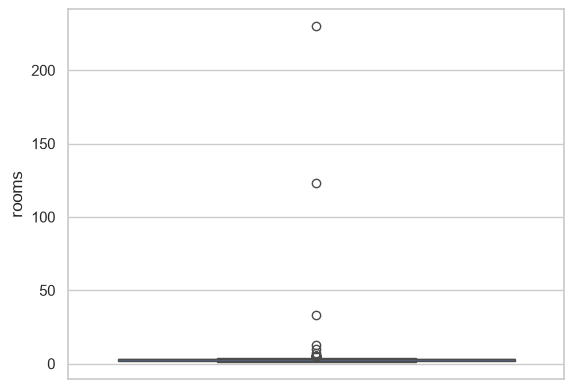

In [66]:
sns.boxplot(df['rooms'])

<Axes: ylabel='bathrooms'>

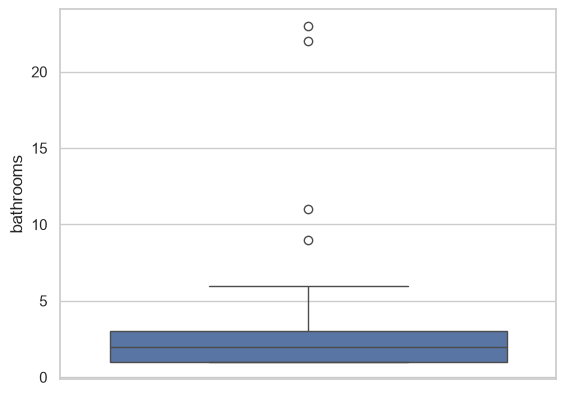

In [67]:
sns.boxplot(df['bathrooms'])

<Axes: ylabel='year_built'>

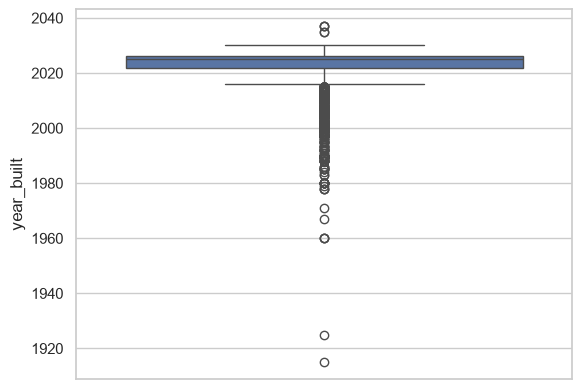

In [68]:
sns.boxplot(df['year_built'])

In [69]:

def remove_outliers_iqr(data, column_name="value"):
    """
    Removes outliers using the IQR method.
    Returns filtered DataFrame.
    """
    Q1 = df[column_name].quantile(0.25)
    Q3 = df[column_name].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return df[(df[column_name] >= lower) & (df[column_name] <= upper)]
cleaned_df = remove_outliers_iqr(df, column_name=['year_built','bathrooms','rooms'])

print(df.shape,cleaned_df.shape)

(4280, 14) (4280, 14)


In [70]:
X=df.drop(['price'],axis=1)
y=df['price']

In [71]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42,stratify=None,test_size=0.20)

In [72]:
X_train.head()

,area_sqm,rooms,bathrooms,floor_level,year_built,view,price_per_sqm,finishing_type,seller_type_Compound Developer,seller_type_Developer,seller_type_Private Owner,payment_method_Cash or Installments,payment_method_Installments
3647,240.0,4.0,3.0,4.0,2020,6,19792.0,0,0.0,0.0,0.0,0.0,0.0
4201,200.0,3.0,2.0,4.0,2025,8,19500.0,3,0.0,0.0,0.0,0.0,0.0
324,130.0,2.0,3.0,1.0,2025,8,25385.0,2,0.0,0.0,0.0,0.0,0.0
2258,210.0,3.0,2.0,9.0,2005,6,23810.0,3,0.0,0.0,0.0,0.0,0.0
805,75.0,3.0,2.0,2.0,2020,8,29333.0,3,0.0,0.0,0.0,0.0,0.0


In [73]:
from sklearn.preprocessing import StandardScaler

In [74]:
scal=StandardScaler()

In [75]:
X_train[['year_built','price_per_sqm']] = scal.fit_transform(
    X_train[['year_built','price_per_sqm']]
)

X_test[['year_built','price_per_sqm']] = scal.transform(
    X_test[['year_built','price_per_sqm']]
)

# Applying ML models

In [86]:
from tqdm import tqdm
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
import lightgbm as lgb
from lightgbm import LGBMRegressor

In [87]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [88]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/14 [00:00<?, ?it/s]

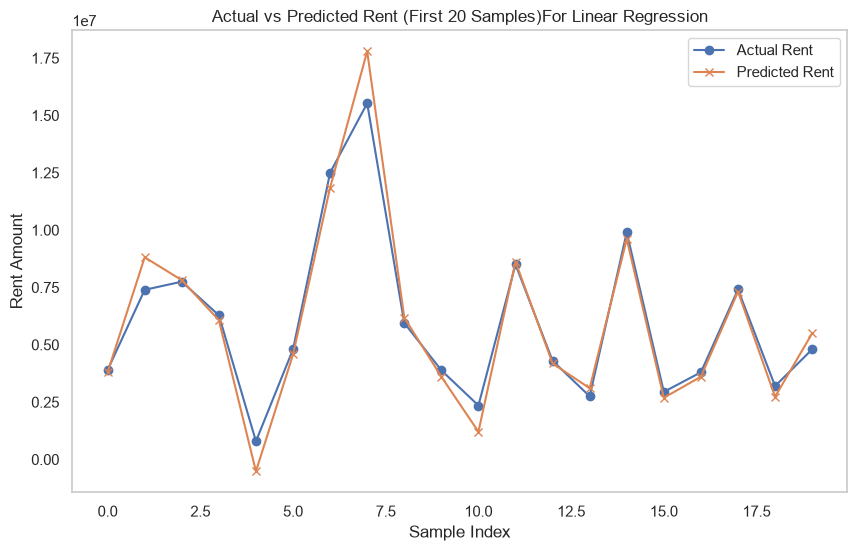

  7%|▋         | 1/14 [00:00<00:02,  6.36it/s]

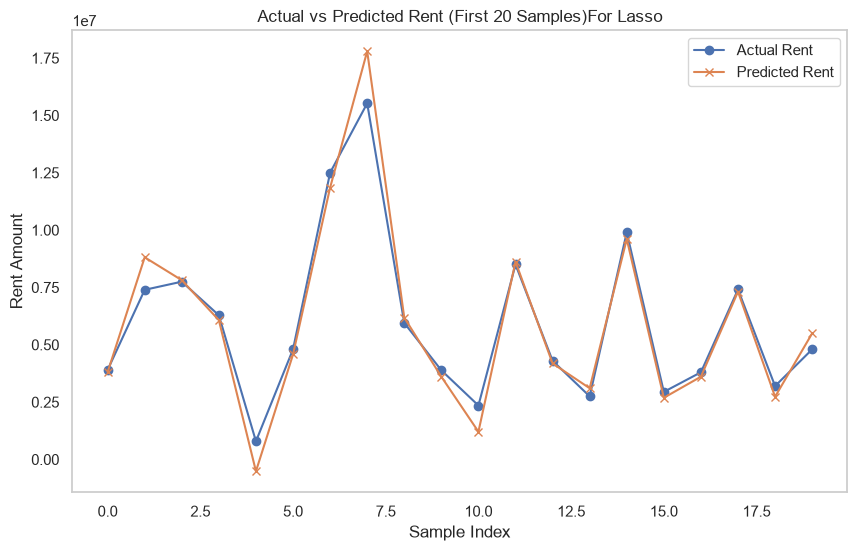

 14%|█▍        | 2/14 [00:00<00:01,  6.71it/s]

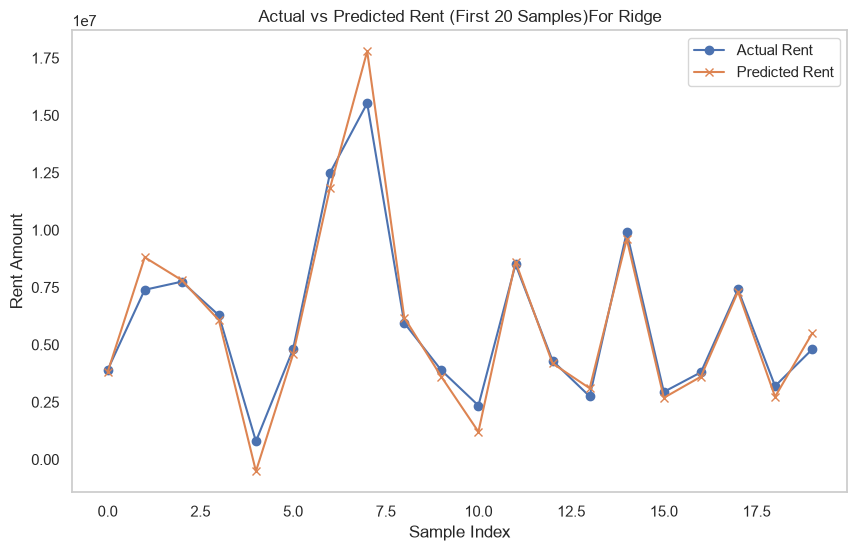

 21%|██▏       | 3/14 [00:00<00:01,  7.10it/s]

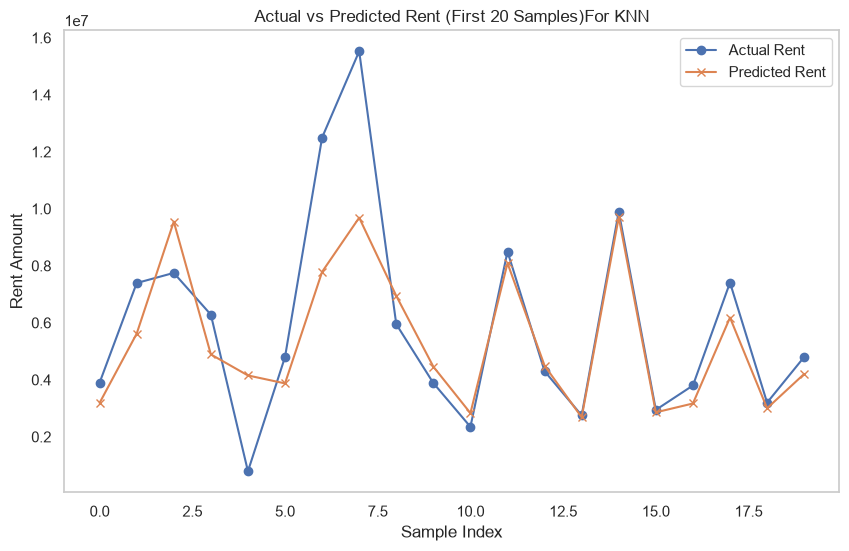

 29%|██▊       | 4/14 [00:00<00:01,  6.81it/s]

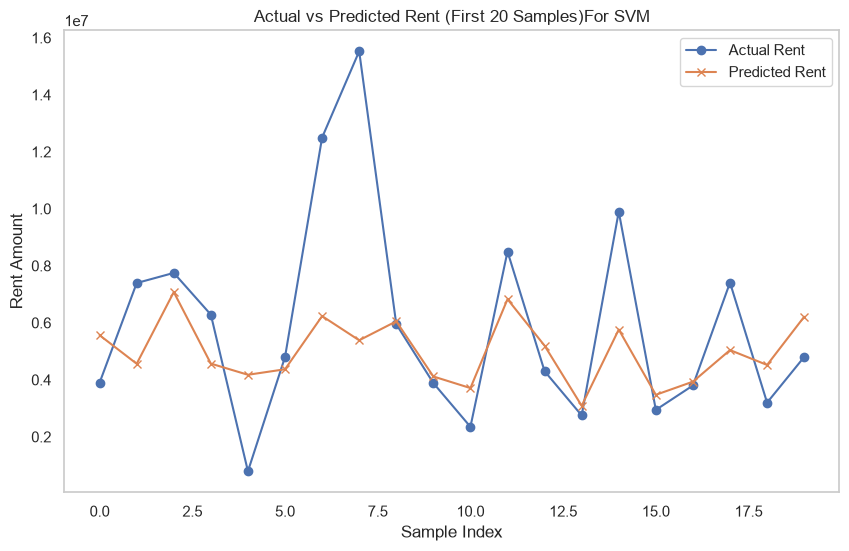

 36%|███▌      | 5/14 [00:01<00:02,  3.82it/s]

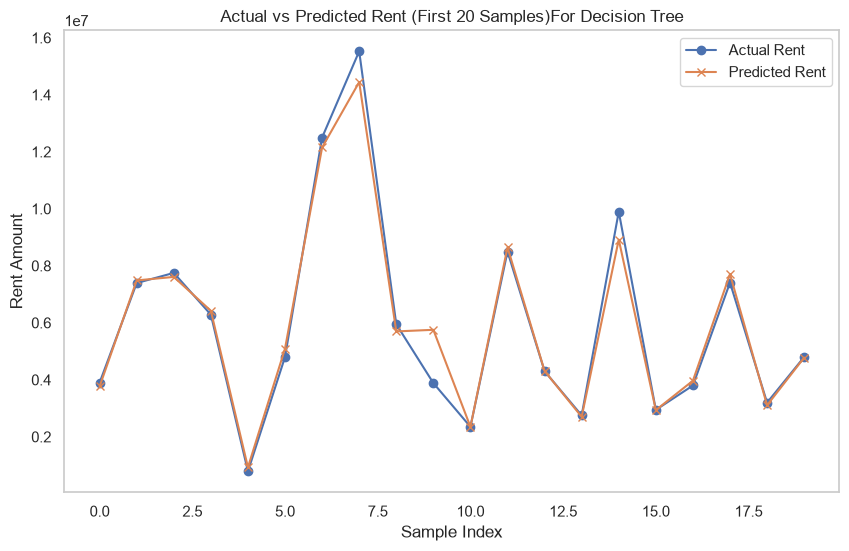

 43%|████▎     | 6/14 [00:01<00:01,  4.54it/s]

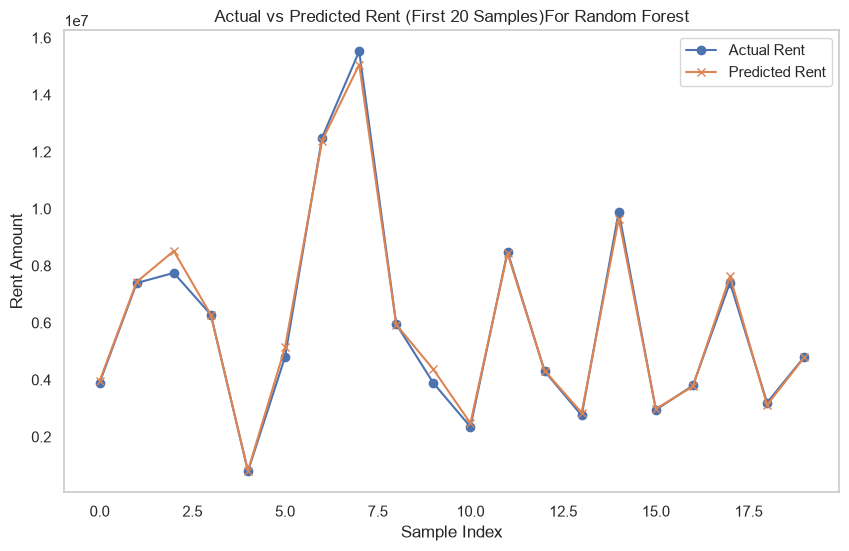

 50%|█████     | 7/14 [00:01<00:01,  3.62it/s]

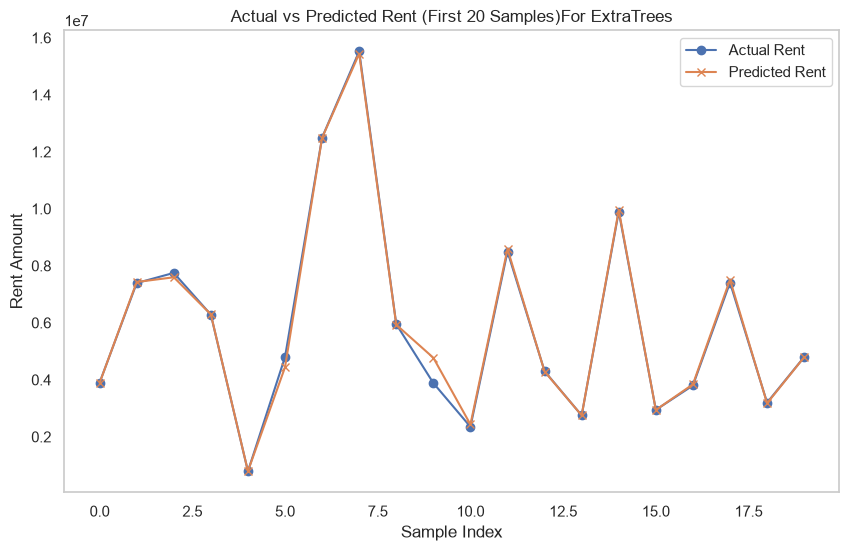

 57%|█████▋    | 8/14 [00:02<00:02,  2.24it/s]

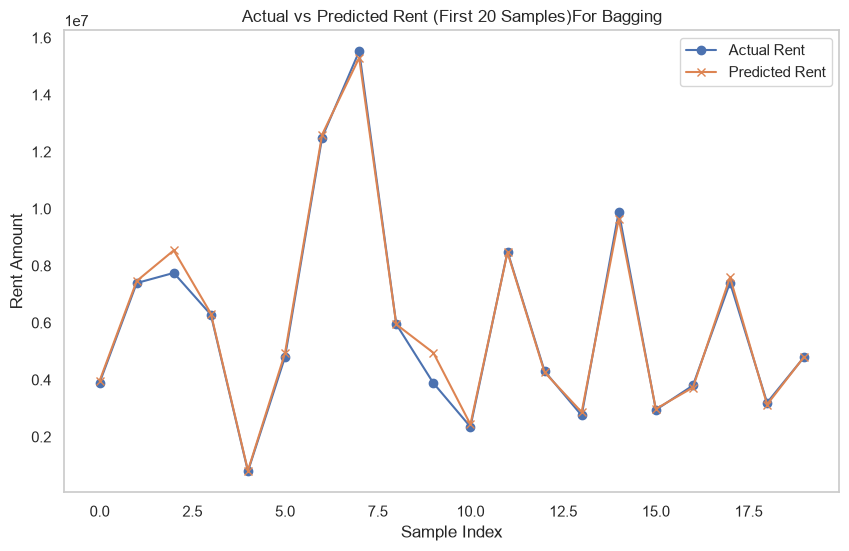

 64%|██████▍   | 9/14 [00:02<00:02,  2.24it/s]

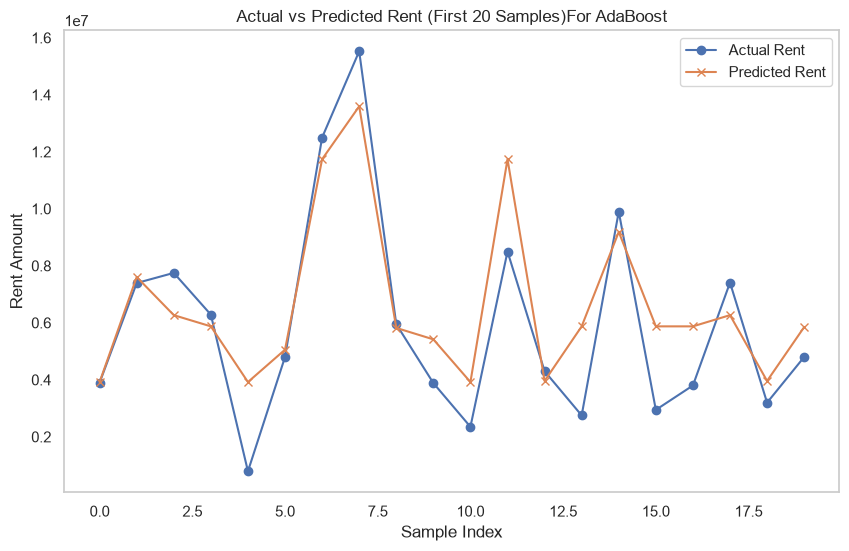

 71%|███████▏  | 10/14 [00:03<00:01,  2.63it/s]

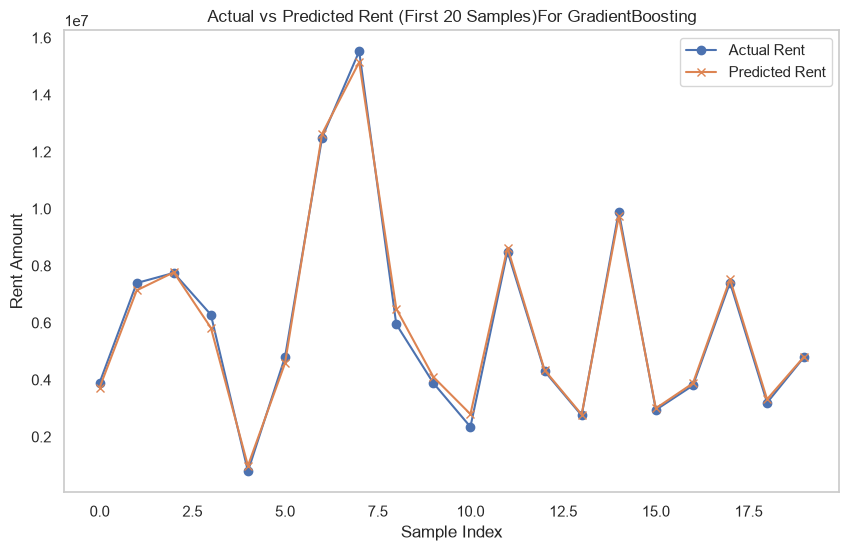

 79%|███████▊  | 11/14 [00:03<00:01,  2.63it/s]

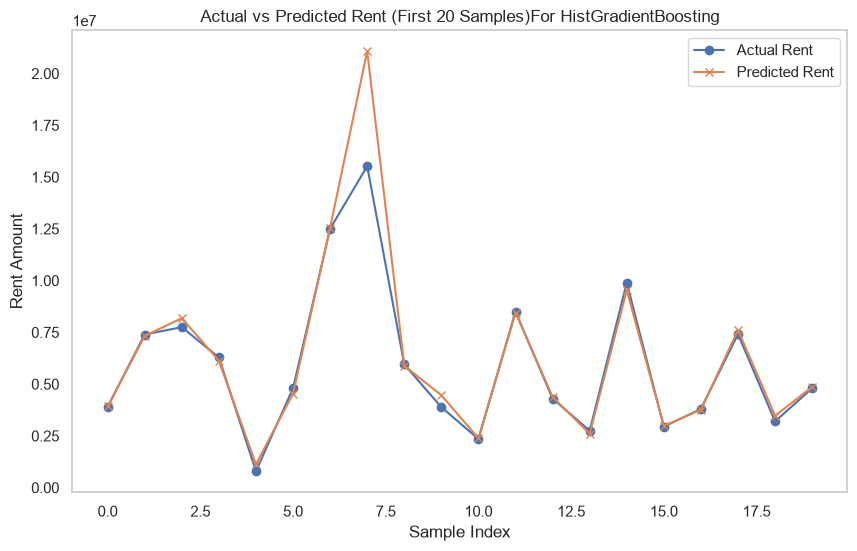

 86%|████████▌ | 12/14 [00:03<00:00,  2.61it/s]

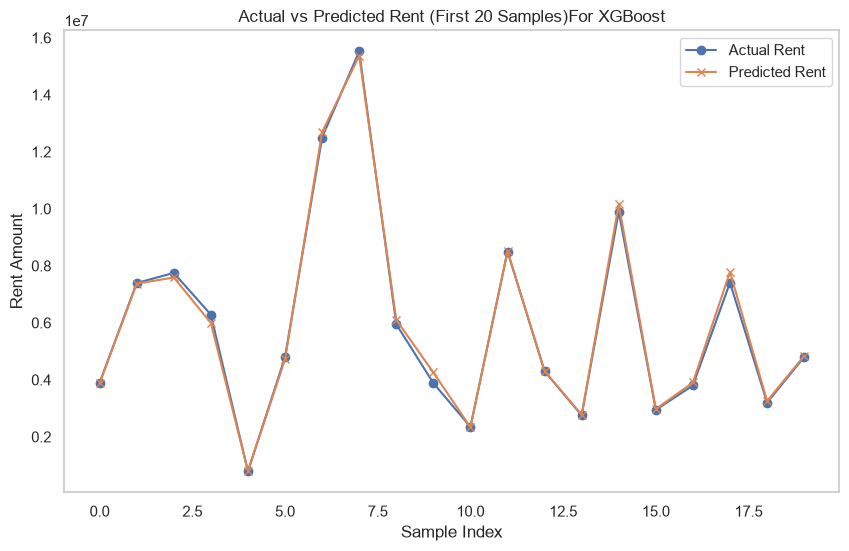

 93%|█████████▎| 13/14 [00:04<00:00,  2.54it/s]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000146 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 565
[LightGBM] [Info] Number of data points in the train set: 3424, number of used features: 12
[LightGBM] [Info] Start training from score 6238463.142815


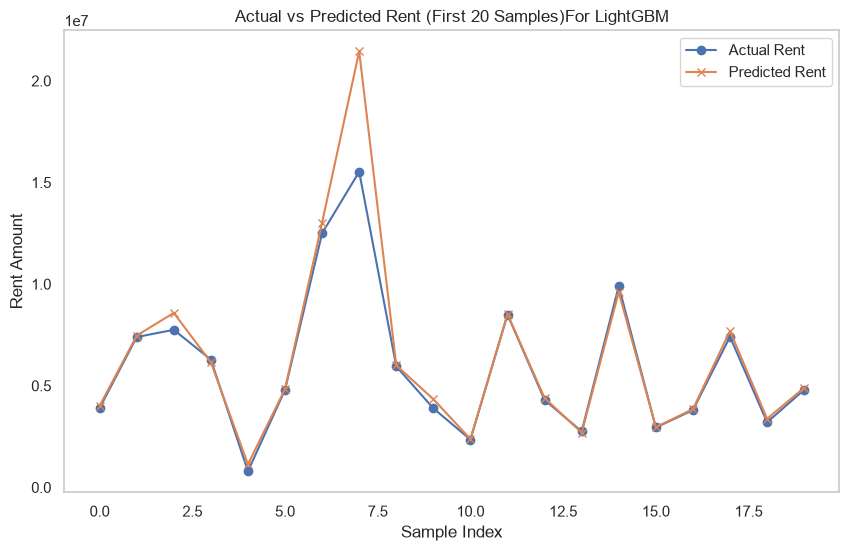

100%|██████████| 14/14 [00:04<00:00,  3.13it/s]


In [89]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)
    
    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [90]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [91]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    #('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [92]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [93]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
GradientBoosting,2.434132e+05,2.583662e+05,4.252399e+11,1.874068e+11,6.521042e+05,4.329051e+05,0.981657,0.988129
ExtraTrees,1.334696e+02,1.717399e+05,1.446816e+07,2.191013e+11,3.803703e+03,4.680825e+05,0.999999,0.986121
Random Forest,1.403060e+05,1.917385e+05,2.017582e+11,2.482784e+11,4.491751e+05,4.982754e+05,0.991297,0.984273
Bagging,1.340049e+05,1.848528e+05,1.676053e+11,2.513078e+11,4.093963e+05,5.013061e+05,0.992770,0.984081
Stacking,1.548730e+05,3.147145e+05,6.363615e+11,1.081441e+12,7.977227e+05,1.039924e+06,0.972550,0.981660
Voting,2.629917e+05,3.147145e+05,2.721560e+11,1.081441e+12,5.216858e+05,1.039924e+06,0.988260,0.975994
Simple Voting,2.629917e+05,3.147145e+05,2.721560e+11,1.081441e+12,5.216858e+05,1.039924e+06,0.988260,0.975994
Decision Tree,1.476299e+05,2.946895e+05,1.159004e+11,3.911023e+11,3.404414e+05,6.253817e+05,0.995001,0.975226
Weighted Voting,3.088080e+05,3.147145e+05,3.493623e+11,1.081441e+12,5.910688e+05,1.039924e+06,0.984930,0.970957
XGBoost,1.489079e+05,2.469421e+05,1.518752e+11,8.637972e+11,3.897117e+05,9.294069e+05,0.993449,0.945284


<Axes: >

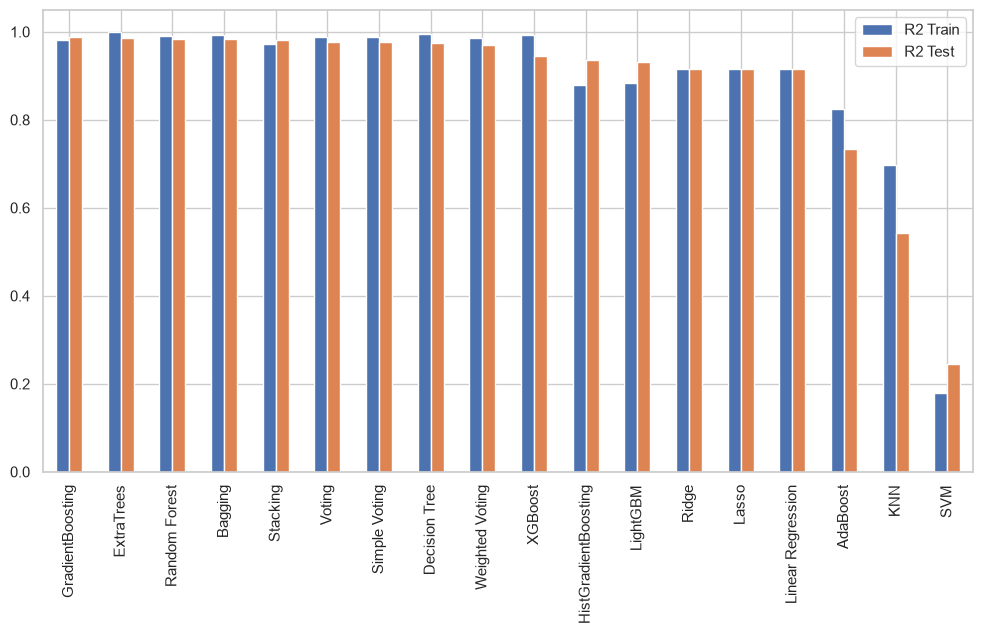

In [94]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

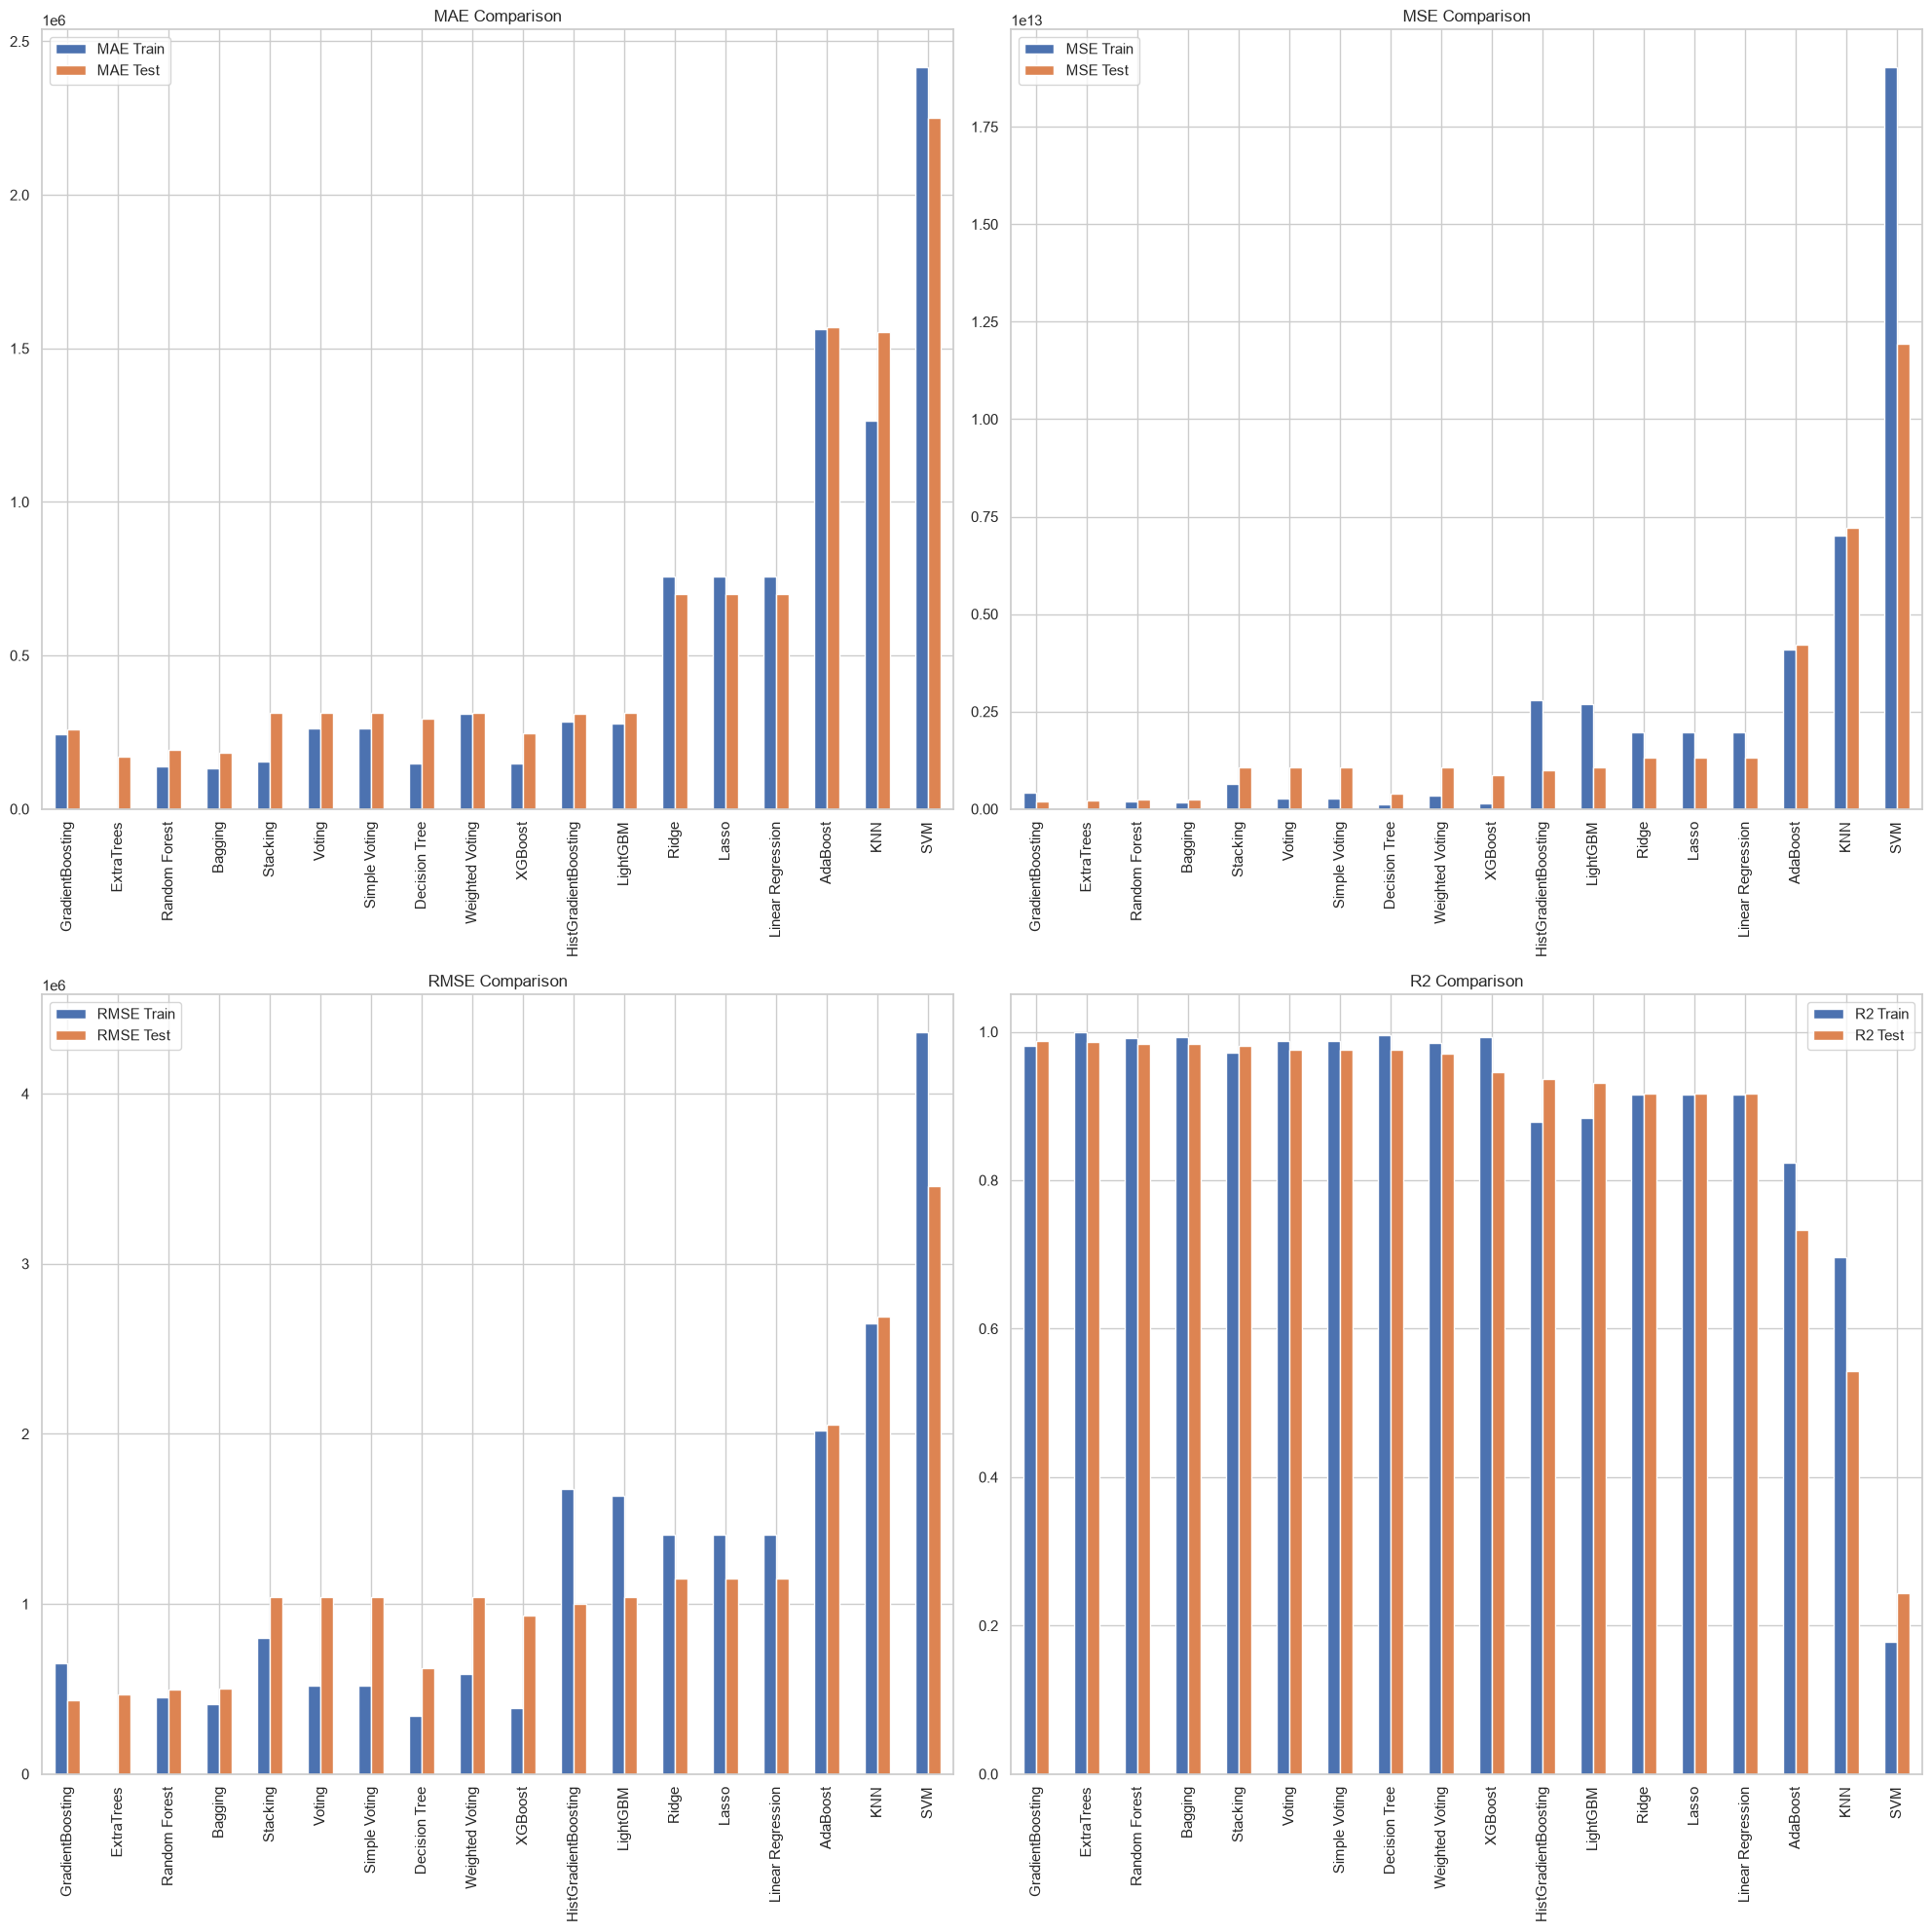

In [95]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)   
    errors_df[col].plot.bar(ax=ax)   
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()